In [76]:
import numpy as np
import pandas as pd
import GEOparse

from scipy.stats import ttest_ind
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from statsmodels.stats.multitest import multipletests

In [77]:
import logging

logging.getLogger("GEOparse").setLevel(logging.ERROR)

In [78]:
gse = GEOparse.get_GEO(
    filepath="C:\\Users\\Asrefanavary\\Autism\\data\\raw\\GSE18123_family.soft"
)

C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\GEOparse\GEOparse.py:401: DtypeWarning: Columns (0: SPOT_ID) have mixed types. Specify dtype option on import or set low_memory=False.
  return read_csv(StringIO(data), index_col=None, sep="\t")


## 1. Dataset Overview

The GSE18123 dataset contains 285 samples measured across two microarray platforms: GPL570 and GPL6244.

For this study, we focus on GPL6244 to maintain a consistent platform for downstream transcriptomic analysis.

In [79]:
print("Number of samples:", len(gse.gsms))
print("Number of platforms:", len(gse.gpls))

Number of samples: 285
Number of platforms: 2


In [80]:
# Inspect the number of samples for each platform

platform_counts = {}

for gsm_id, gsm in gse.gsms.items():
    platform = gsm.metadata["platform_id"][0]
    platform_counts[platform] = platform_counts.get(platform, 0) + 1

platform_counts

{'GPL570': 99, 'GPL6244': 186}

In [81]:
# Select samples measured on GPL6244

GPL6244_SAMPLES = [
    gsm_id
    for gsm_id, gsm in gse.gsms.items()
    if gsm.metadata["platform_id"][0] == "GPL6244"
]

print("Number of GPL6244 samples:", len(GPL6244_SAMPLES))
print("First 10 samples:", GPL6244_SAMPLES[:10])

Number of GPL6244 samples: 186
First 10 samples: ['GSM650655', 'GSM650656', 'GSM650657', 'GSM650658', 'GSM650659', 'GSM650660', 'GSM650661', 'GSM650662', 'GSM650663', 'GSM650664']


## 2. Sample Metadata

Sample-level metadata were extracted from the GEO annotations for the 186 samples measured on GPL6244.

The metadata include diagnostic status, sex, age, and other available clinical characteristics.

In [82]:
metadata_rows = []

for sample_id in GPL6244_SAMPLES:
    gsm = gse.gsms[sample_id]
    characteristics = gsm.metadata["characteristics_ch1"]

    row = {
        "sample_id": sample_id,
        "platform": gsm.metadata["platform_id"][0],
        "source": gsm.metadata["source_name_ch1"][0],
    }

    for item in characteristics:
        key, value = item.split(":", 1)
        row[key.strip()] = value.strip()

    metadata_rows.append(row)

metadata = pd.DataFrame(metadata_rows)

print("Metadata shape:", metadata.shape)
metadata.head()

Metadata shape: (186, 24)


,sample_id,platform,source,diagnosis,gender,age at blood drawing (months),race,ethnicity,hours (minutes since last caloric intake),chronic diseases,...,gastrointestinal disorder,autoimmune disorder,genetic testing,birth defects,ct,mri,medications/vitamin names,cerebral palsy,seizure,other diseases
0,GSM650655,GPL6244,Blood,ASPERGER'S DISORDER,male,156,Caucasian,Non-Hispanic,: 3:25,-,...,-,-,-,-,-,-,"ibuprofen, excedrine, multivitamin",-,-,-
1,GSM650656,GPL6244,Blood,AUTISM,male,168,Caucasian,Non-Hispanic,: 0:40,-,...,-,-,-,-,-,-,"Biaxin, Singulair, Lexapro, Biaxin, tylenol, e...",-,-,-
2,GSM650657,GPL6244,Blood,CONTROL,male,228,Black,Non-Hispanic,: 7:35,-,...,-,-,-,-,-,-,tylenol,-,-,-
3,GSM650658,GPL6244,Blood,AUTISM,male,60,Caucasian,Non-Hispanic,: 1:30,-,...,yes,-,-,-,-,-,"OTC cold medications, Risperdal, multivitamin",-,-,-
4,GSM650659,GPL6244,Blood,AUTISM,male,36,Caucasian,Non-Hispanic,: 5:00,-,...,yes,-,-,-,-,-,"pediapops, multivitamin, flouride",-,-,-


### Diagnostic Groups

The diagnostic labels were inspected to distinguish ASD subtypes from control samples.

In [83]:
metadata["diagnosis"].value_counts(dropna=False)

diagnosis
CONTROL                82
PDD-NOS                48
AUTISM                 41
ASPERGER'S DISORDER    15
Name: count, dtype: int64

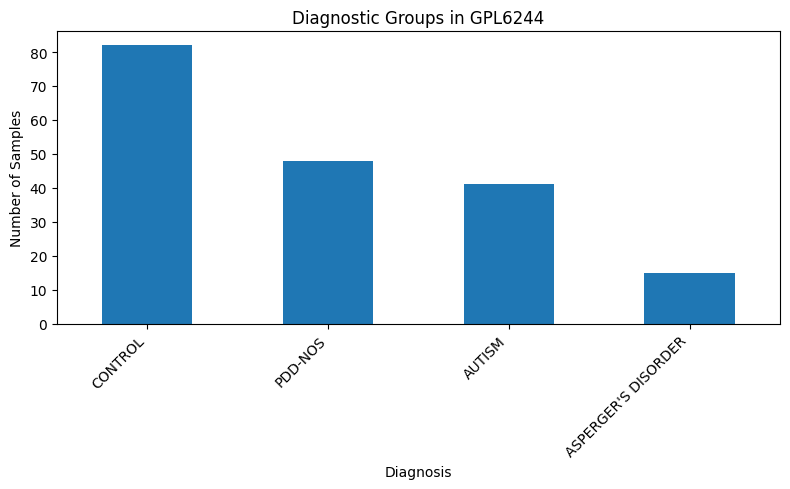

In [84]:
import matplotlib.pyplot as plt

diagnosis_counts = metadata["diagnosis"].value_counts()

plt.figure(figsize=(8, 5))
diagnosis_counts.plot(kind="bar")
plt.title("Diagnostic Groups in GPL6244")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [85]:
metadata["gender"].value_counts(dropna=False)

gender
male      128
female     58
Name: count, dtype: int64

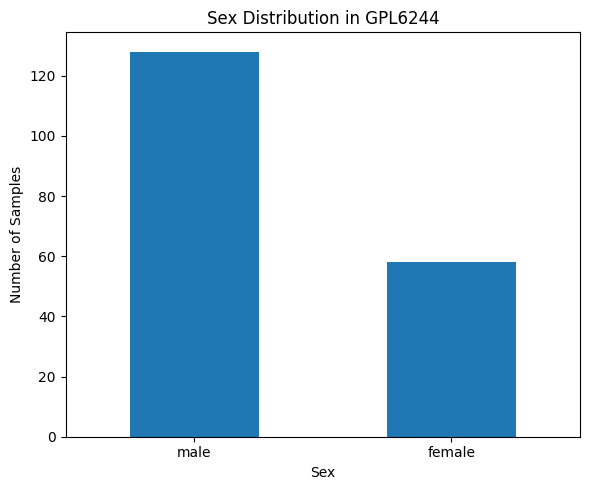

In [86]:
gender_counts = metadata["gender"].value_counts()

plt.figure(figsize=(6, 5))
gender_counts.plot(kind="bar")
plt.title("Sex Distribution in GPL6244")
plt.xlabel("Sex")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [87]:
pd.crosstab(
    metadata["diagnosis"],
    metadata["gender"]
)

gender,female,male
diagnosis,,
ASPERGER'S DISORDER,2,13
AUTISM,10,31
CONTROL,34,48
PDD-NOS,12,36


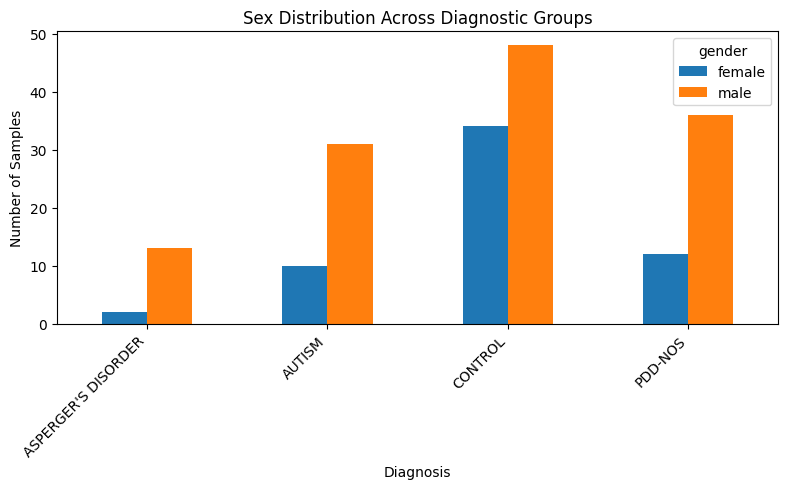

In [88]:
sex_by_diagnosis = pd.crosstab(
    metadata["diagnosis"],
    metadata["gender"]
)

sex_by_diagnosis.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sex Distribution Across Diagnostic Groups")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Binary Diagnostic Group

For binary classification, the three ASD diagnostic subtypes (Autism, Asperger's Disorder, and PDD-NOS) are grouped as ASD, while the control samples are retained as the Control group.

In [89]:
# Create a binary diagnostic label

metadata["group"] = metadata["diagnosis"].apply(
    lambda x: "Control" if x == "CONTROL" else "ASD"
)

metadata["group"].value_counts()

group
ASD        104
Control     82
Name: count, dtype: int64

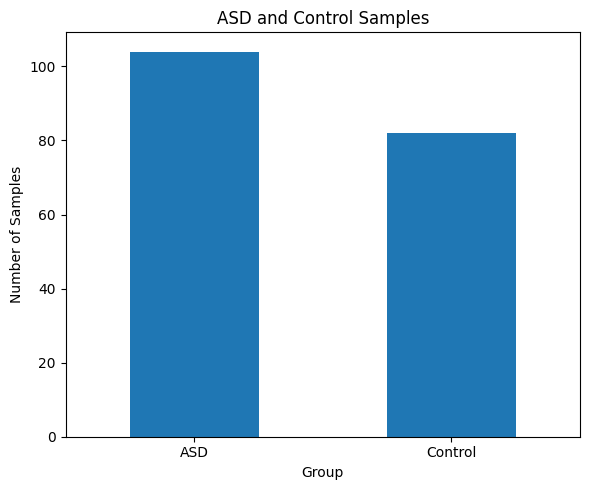

In [90]:
group_counts = metadata["group"].value_counts()

plt.figure(figsize=(6, 5))
group_counts.plot(kind="bar")
plt.title("ASD and Control Samples")
plt.xlabel("Group")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [91]:
metadata["age_months"] = pd.to_numeric(
    metadata["age at blood drawing (months)"],
    errors="coerce"
)

metadata["age_months"].describe()

count    186.000000
mean      96.806452
std       52.409460
min       24.000000
25%       51.250000
50%       84.000000
75%      136.500000
max      264.000000
Name: age_months, dtype: float64

In [92]:
print("Missing age:", metadata["age_months"].isna().sum())

Missing age: 0


In [93]:
metadata.groupby("group")["age_months"].describe()

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
ASD,104.0,97.096154,48.612300,24.0,60.0,87.5,132.0,252.0
Control,82.0,96.439024,57.168172,24.0,49.0,80.0,144.0,264.0


<Figure size 700x500 with 0 Axes>

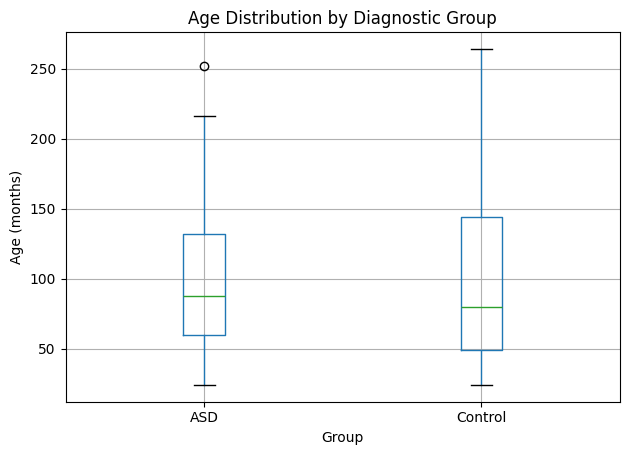

In [94]:
plt.figure(figsize=(7, 5))

metadata.boxplot(
    column="age_months",
    by="group"
)

plt.title("Age Distribution by Diagnostic Group")
plt.suptitle("")
plt.xlabel("Group")
plt.ylabel("Age (months)")
plt.tight_layout()
plt.show()

## 3. Clean Sample Metadata

A cleaned sample-level metadata table was created containing the variables required for downstream analysis, including sample ID, diagnosis, binary diagnostic group, sex, age, and platform.

In [95]:
metadata_clean = metadata[
    [
        "sample_id",
        "diagnosis",
        "group",
        "gender",
        "age_months",
        "platform",
        "source"
    ]
].copy()

metadata_clean.head()

,sample_id,diagnosis,group,gender,age_months,platform,source
0,GSM650655,ASPERGER'S DISORDER,ASD,male,156,GPL6244,Blood
1,GSM650656,AUTISM,ASD,male,168,GPL6244,Blood
2,GSM650657,CONTROL,Control,male,228,GPL6244,Blood
3,GSM650658,AUTISM,ASD,male,60,GPL6244,Blood
4,GSM650659,AUTISM,ASD,male,36,GPL6244,Blood


In [96]:
metadata_clean.shape

(186, 7)

## 4. Expression Data Extraction

Expression measurements were extracted for the 186 samples profiled on GPL6244.

The resulting matrix will contain probes as rows and samples as columns and will be used as the starting point for downstream preprocessing and feature selection.

In [97]:
# Extract expression tables for GPL6244 samples

expression_tables = []

for sample_id in GPL6244_SAMPLES:
    gsm = gse.gsms[sample_id]
    
    table = gsm.table.copy()
    table["sample_id"] = sample_id
    
    expression_tables.append(table)

print(f"Number of expression tables: {len(expression_tables)}")

Number of expression tables: 186


In [98]:
# Build probe × sample expression matrix

expression_matrix = pd.concat(
    [
        table.set_index("ID_REF")["VALUE"].rename(sample_id)
        for table, sample_id in zip(expression_tables, GPL6244_SAMPLES)
    ],
    axis=1
)

print("Expression matrix shape:", expression_matrix.shape)
expression_matrix.head()

Expression matrix shape: (33297, 186)


,GSM650655,GSM650656,GSM650657,GSM650658,GSM650659,GSM650660,GSM650661,GSM650662,GSM650663,GSM650664,...,GSM650944,GSM650946,GSM650950,GSM650951,GSM650954,GSM650959,GSM650968,GSM650969,GSM650970,GSM650975
ID_REF,,,,,,,,,,,,,,,,,,,,,
7892501,9.67160,79.14403,5.01300,25.72981,13.91895,50.35127,0.00710,21.05778,17.47698,21.28318,...,3.29406,11.12443,10.39181,8.97071,10.81198,4.68356,6.86785,17.74369,25.06523,0.20273
7892502,122.91175,104.38295,72.69745,145.16537,135.98053,175.38919,76.26821,132.59755,71.81705,111.28992,...,91.05885,111.46063,122.56646,114.05913,118.40833,108.89500,116.92853,81.63403,125.67404,162.58068
7892503,151.17249,67.21808,121.55192,95.46856,142.72005,139.20885,76.43104,129.48506,28.21930,117.98628,...,68.07263,33.71550,37.54560,55.18136,51.72213,43.75254,39.59656,53.28886,52.58810,41.59902
7892504,1935.89058,1302.83223,2160.06200,1962.15620,2244.96492,1881.05895,1872.58446,2172.58165,1855.87522,2178.26544,...,911.73272,938.98578,966.40733,968.54483,952.49003,1265.23364,1218.08127,1268.45347,1394.62097,1005.47667
7892505,21.14810,13.81453,23.37327,21.44558,20.51383,34.54137,21.32496,20.20900,18.05306,31.27404,...,19.42496,12.85209,16.61253,22.24478,21.30586,14.24507,18.37833,20.56806,21.40529,17.12014


In [99]:
print(
    "Total missing values:",
    expression_matrix.isna().sum().sum()
)

Total missing values: 0


In [100]:
print(
    "Duplicated probe IDs:",
    expression_matrix.index.duplicated().sum()
)

Duplicated probe IDs: 0


### Expression Distribution Across Samples

The distribution of expression values was examined across samples to identify major differences in overall signal intensity and potential technical outliers.

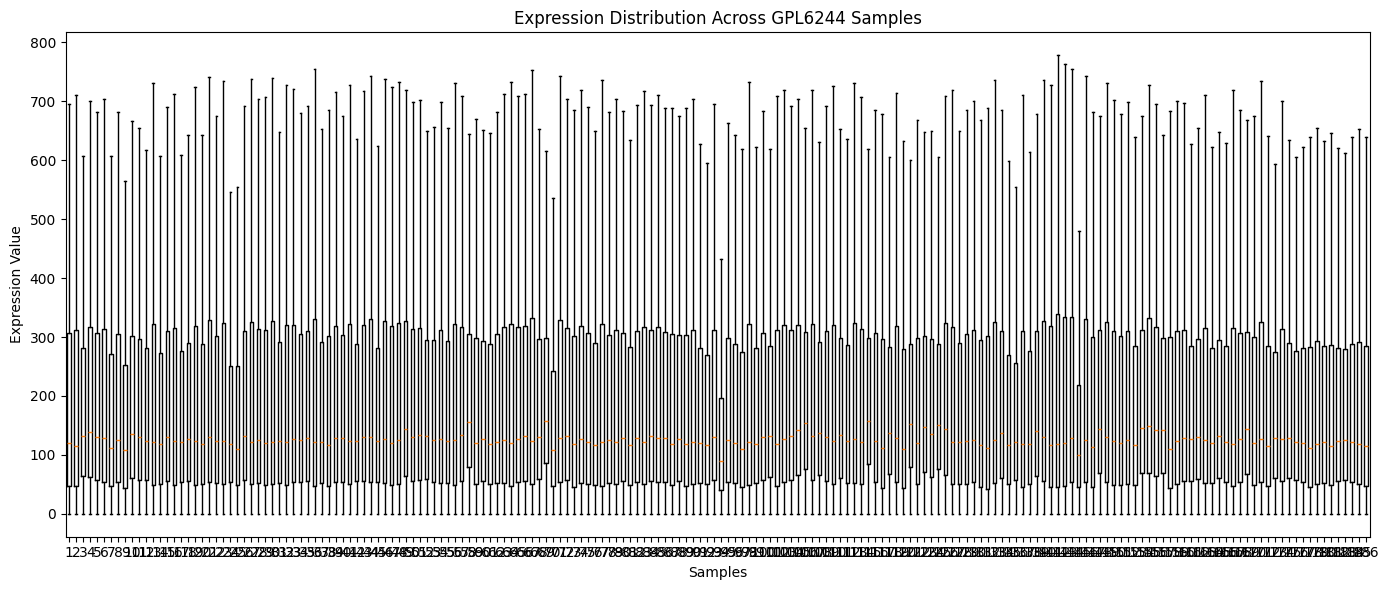

In [101]:
plt.figure(figsize=(14, 6))

plt.boxplot(
    expression_matrix.values,
    showfliers=False
)

plt.title("Expression Distribution Across GPL6244 Samples")
plt.xlabel("Samples")
plt.ylabel("Expression Value")

plt.tight_layout()
plt.show()

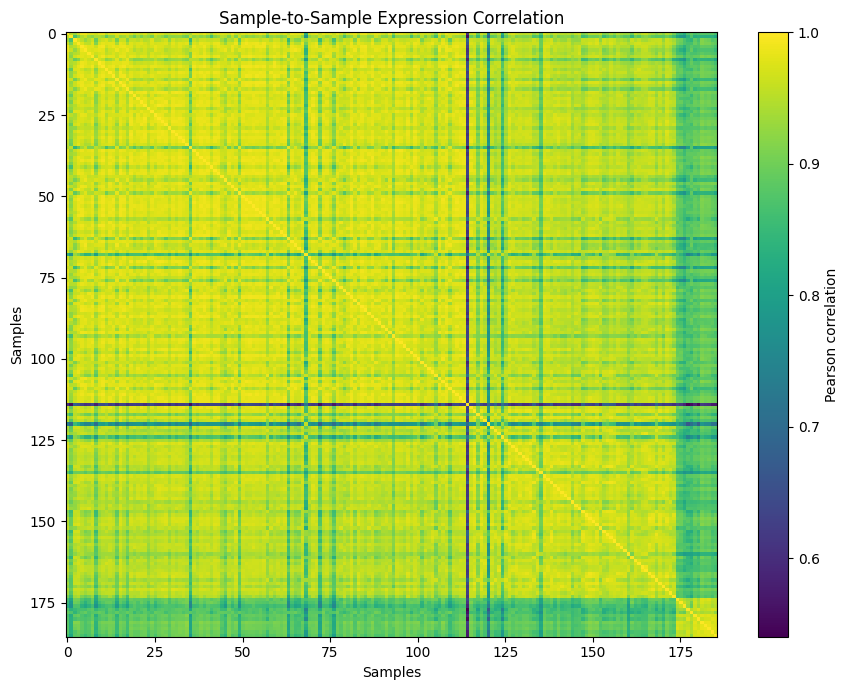

In [102]:
sample_correlation = expression_matrix.corr()

plt.figure(figsize=(9, 7))

plt.imshow(
    sample_correlation,
    aspect="auto"
)

plt.colorbar(label="Pearson correlation")
plt.title("Sample-to-Sample Expression Correlation")
plt.xlabel("Samples")
plt.ylabel("Samples")

plt.tight_layout()
plt.show()

## Probe Annotation and Gene Mapping

The expression matrix contains probe-level measurements from the Affymetrix Human Gene 1.0 ST Array (GPL6244).

Before downstream statistical analysis and machine learning, probes need to be mapped to gene identifiers. This step is important because multiple probes may correspond to the same gene, and some probes may not have a valid gene annotation.

We therefore first inspect the GPL6244 platform annotation and determine which identifiers are available for mapping probes to genes.

In [103]:
platform = gse.gpls["GPL6244"]

print(platform.table.shape)
print(platform.table.columns.tolist())

(33297, 12)
['ID', 'GB_LIST', 'SPOT_ID', 'seqname', 'RANGE_GB', 'RANGE_STRAND', 'RANGE_START', 'RANGE_STOP', 'total_probes', 'gene_assignment', 'mrna_assignment', 'category']


## Inspecting Probe-to-Gene Annotation

The GPL6244 platform annotation provides a `gene_assignment` field for each probe. We inspect representative entries to determine the annotation format before performing probe-to-gene mapping.

In [104]:
annotation = platform.table.copy()

annotation[["ID", "gene_assignment", "mrna_assignment", "category"]].head(10)

,ID,gene_assignment,mrna_assignment,category
0,7896736,---,NONHSAT060105 // NONCODE // Non-coding transcr...,main
1,7896738,ENST00000328113 // OR4G2P // olfactory recepto...,ENST00000328113 // ENSEMBL // havana:known chr...,main
2,7896740,"NM_001004195 // OR4F4 // olfactory receptor, f...",NM_001004195 // RefSeq // Homo sapiens olfacto...,main
3,7896742,NR_024437 // LOC728323 // uncharacterized LOC7...,NR_024437 // RefSeq // Homo sapiens uncharacte...,main
4,7896744,"NM_001005221 // OR4F29 // olfactory receptor, ...",NM_001005221 // RefSeq // Homo sapiens olfacto...,main
5,7896746,ENST00000387377 // MT-TM // mitochondrially en...,ENST00000387377 // ENSEMBL // mt_genbank_impor...,main
6,7896748,ENST00000387382 // MT-TW // mitochondrially en...,ENST00000387382 // ENSEMBL // mt_genbank_impor...,main
7,7896750,ENST00000387419 // MT-TD // mitochondrially en...,ENST00000387419 // ENSEMBL // mt_genbank_impor...,main
8,7896752,ENST00000387421 // MT-TK // mitochondrially en...,ENST00000387421 // ENSEMBL // mt_genbank_impor...,main
9,7896754,ENST00000540997 // LOC100287497 // uncharacter...,ENST00000540997 // ENSEMBL // havana:known chr...,main


## Assessing Probe Annotation Ambiguity

A probe may be annotated to multiple transcripts or genes. To avoid assigning an expression measurement to an incorrect gene, probes with ambiguous mappings to multiple distinct gene symbols will be excluded from the primary gene-level analysis.

First, we quantify the extent of missing and ambiguous gene annotation.

In [105]:
def extract_gene_symbols(annotation_string):
    if pd.isna(annotation_string) or annotation_string == "---":
        return []
    
    records = annotation_string.split(" /// ")
    gene_symbols = []
    
    for record in records:
        fields = [field.strip() for field in record.split(" // ")]
        
        if len(fields) >= 2:
            gene_symbol = fields[1]
            
            if gene_symbol not in {"---", ""}:
                gene_symbols.append(gene_symbol)
    
    return sorted(set(gene_symbols))


annotation["gene_symbols"] = annotation["gene_assignment"].apply(
    extract_gene_symbols
)

annotation["n_gene_symbols"] = annotation["gene_symbols"].apply(len)

print("Total probes:", len(annotation))
print("Probes with no gene annotation:", (annotation["n_gene_symbols"] == 0).sum())
print("Probes mapped to exactly one gene:", (annotation["n_gene_symbols"] == 1).sum())
print("Probes mapped to multiple genes:", (annotation["n_gene_symbols"] > 1).sum())

Total probes: 33297
Probes with no gene annotation: 8004
Probes mapped to exactly one gene: 22153
Probes mapped to multiple genes: 3140


## Filtering to Unambiguous Probe-to-Gene Mappings

For the primary analysis, we retain only probes that map unambiguously to a single gene symbol.

Probes without a gene annotation and probes mapped to multiple distinct genes are excluded from the primary gene-level analysis. This conservative strategy reduces the risk of assigning a probe expression profile to the wrong gene.

In [106]:
unambiguous_annotation = annotation[
    annotation["n_gene_symbols"] == 1
].copy()

unambiguous_annotation["gene_symbol"] = (
    unambiguous_annotation["gene_symbols"].str[0]
)

print("Unambiguous probes:", len(unambiguous_annotation))
print(
    "Unique genes represented:",
    unambiguous_annotation["gene_symbol"].nunique()
)

Unambiguous probes: 22153
Unique genes represented: 21408


In [107]:
probe_counts_per_gene = (
    unambiguous_annotation["gene_symbol"]
    .value_counts()
)

print("Genes with one probe:", (probe_counts_per_gene == 1).sum())
print("Genes with multiple probes:", (probe_counts_per_gene > 1).sum())
print("Maximum probes for one gene:", probe_counts_per_gene.max())

Genes with one probe: 20833
Genes with multiple probes: 575
Maximum probes for one gene: 26


## Aggregating Multiple Probes at the Gene Level

After restricting the analysis to unambiguous probe-to-gene mappings, multiple probes may still represent the same gene.

To obtain one expression feature per gene, expression values from probes targeting the same gene are aggregated using the median across probes. The median is a robust summary that reduces the influence of unusually high or low probe-level measurements.

This produces a gene-level expression matrix suitable for downstream statistical analysis and machine learning.

In [108]:
# Keep only probes with an unambiguous gene mapping
probe_expression = expression_matrix.loc[unambiguous_annotation["ID"]].copy()

# Add gene symbol column
probe_expression["gene_symbol"] = (
    unambiguous_annotation.set_index("ID").loc[probe_expression.index, "gene_symbol"].values
)

# Aggregate multiple probes belonging to the same gene using MEAN (matches Section II-B of the paper)
gene_expression = probe_expression.groupby("gene_symbol").mean()

print("Gene-level expression matrix shape:", gene_expression.shape)

Gene-level expression matrix shape: (21408, 186)


## Inspecting Expression Distribution on a Logarithmic Scale

The gene-level expression values show a strongly right-skewed distribution, with a median of approximately 127 and a maximum above 167,000.

Because the dataset was already processed using PLIER, the original expression matrix will not be transformed at this stage. Instead, a log2-transformed copy is used only for visualization to better assess the overall distribution.

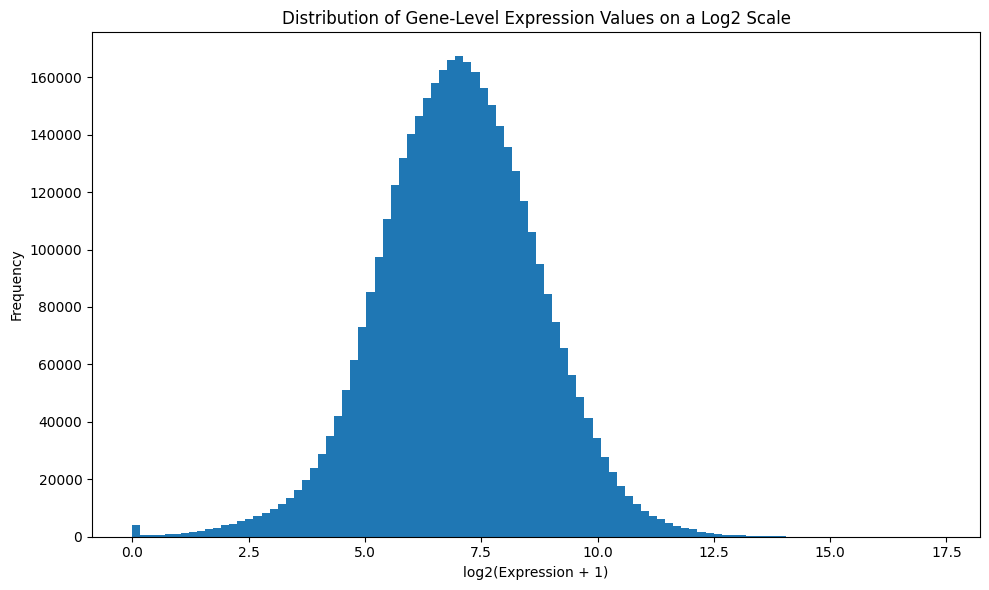

In [109]:
gene_expression_log2 = np.log2(gene_expression + 1)

plt.figure(figsize=(10, 6))

plt.hist(
    gene_expression_log2.values.flatten(),
    bins=100
)

plt.xlabel("log2(Expression + 1)")
plt.ylabel("Frequency")
plt.title("Distribution of Gene-Level Expression Values on a Log2 Scale")

plt.tight_layout()
plt.show()

In [110]:
sample_qc = pd.DataFrame({
    "median": gene_expression_log2.median(axis=0),
    "mean": gene_expression_log2.mean(axis=0),
    "std": gene_expression_log2.std(axis=0),
    "q1": gene_expression_log2.quantile(0.25, axis=0),
    "q3": gene_expression_log2.quantile(0.75, axis=0)
})

sample_qc["IQR"] = sample_qc["q3"] - sample_qc["q1"]

sample_qc.sort_values("median")

,median,mean,std,q1,q3,IQR
GSM650766,6.576067,6.548785,1.666058,5.593573,7.559144,1.965570
GSM650854,6.731641,6.696028,1.675464,5.757191,7.712766,1.955575
GSM650829,6.823734,6.782009,1.898914,5.585762,8.049899,2.464137
GSM650663,6.827456,6.771161,1.714079,5.688170,7.899913,2.211744
GSM650769,6.833044,6.804984,1.805110,5.643316,8.020066,2.376751
...,...,...,...,...,...,...
GSM650809,7.258976,7.253357,1.411812,6.391750,8.119148,1.727398
GSM650830,7.262062,7.224042,1.354200,6.503947,8.010377,1.506430
GSM650714,7.291516,7.281693,1.407536,6.449054,8.125632,1.676578
GSM650725,7.305054,7.313313,1.314322,6.593095,8.059419,1.466324


In [111]:
print("Median range:")
print(sample_qc["median"].min(), "to", sample_qc["median"].max())

print("\nIQR range:")
print(sample_qc["IQR"].min(), "to", sample_qc["IQR"].max())

Median range:
6.5760673685232245 to 7.3051536166266455

IQR range:
1.4663240479023534 to 2.686874641657642


In [112]:
print("Lowest median samples:")
print(sample_qc.nsmallest(5, "median"))

print("\nHighest median samples:")
print(sample_qc.nlargest(5, "median"))

Lowest median samples:
             median      mean       std        q1        q3       IQR
GSM650766  6.576067  6.548785  1.666058  5.593573  7.559144  1.965570
GSM650854  6.731641  6.696028  1.675464  5.757191  7.712766  1.955575
GSM650829  6.823734  6.782009  1.898914  5.585762  8.049899  2.464137
GSM650663  6.827456  6.771161  1.714079  5.688170  7.899913  2.211744
GSM650769  6.833044  6.804984  1.805110  5.643316  8.020066  2.376751

Highest median samples:
             median      mean       std        q1        q3       IQR
GSM650824  7.305154  7.314800  1.314598  6.570413  8.075631  1.505218
GSM650725  7.305054  7.313313  1.314322  6.593095  8.059419  1.466324
GSM650714  7.291516  7.281693  1.407536  6.449054  8.125632  1.676578
GSM650830  7.262062  7.224042  1.354200  6.503947  8.010377  1.506430
GSM650809  7.258976  7.253357  1.411812  6.391750  8.119148  1.727398


In [113]:
# 1. Identify all unique genes that map to chromosome Y using the platform annotation
y_annot_mask = unambiguous_annotation["seqname"].astype(str).str.upper().str.contains("CHRY|^Y$", regex=True)
true_y_genes = unambiguous_annotation.loc[y_annot_mask, "gene_symbol"].unique().tolist()

print(f"Total Y-linked genes found in annotation: {len(true_y_genes)}")
print("Y-linked genes in annotation:", true_y_genes)

# 2. Convert to uppercase for exact matching against expression matrix index
genes_to_remove_upper = {gene.strip().upper() for gene in true_y_genes}

# 3. Identify matches in the log2 expression matrix
normalized_index = gene_expression_log2.index.to_series().astype(str).str.strip().str.upper()
mask_y_genes = normalized_index.isin(genes_to_remove_upper)

removed_genes = gene_expression_log2.index[mask_y_genes].tolist()

# 4. Remove all identified Y-linked genes
gene_expression_noY = gene_expression_log2.loc[~mask_y_genes.to_numpy()].copy()

print("\nOriginal matrix shape:", gene_expression_log2.shape)
print("Final matrix shape:", gene_expression_noY.shape)
print("Total rows removed:", len(removed_genes))
print("Removed genes:", sorted(removed_genes))

Total Y-linked genes found in annotation: 54
Y-linked genes in annotation: ['PLCXD1', 'SHOX', 'CSF2RA', 'IL3RA', 'ASMTL-AS1', 'CD99', 'RNU6-1334P', 'RPS4Y1', 'ZFY', 'RNU2-57P', 'TBL1Y', 'PRKY', 'TTTY12', 'RNA5-8SP6', 'MXRA5P1', 'RN7SL702P', 'USP9Y', 'DDX3Y', 'TMSB4Y', 'KALP', 'NLGN4Y', 'TXLNGY', 'EIF1AY', 'RPS4Y2', 'TSPY14P', 'RN7SL818P', 'RNU6-1314P', 'ANKRD36P1', 'SPRY3', 'VAMP7', 'SLC25A6', 'ASMTL', 'P2RY8', 'SRY', 'RNU6-303P', 'EIF4A1P2', 'AMELY', 'RN7SKP282', 'RNU6-521P', 'TTTY11', 'RBMY1A3P', 'RNA5SP518', 'RNA5SP519', 'UTY', 'CD24', 'RNU6-255P', 'BCORP1', 'KDM5D', 'TTTY10', 'ERVH-6', 'PRORY', 'RBMY2TP', 'TTTY13', 'TTTY5']

Original matrix shape: (21408, 186)
Final matrix shape: (21354, 186)
Total rows removed: 54
Removed genes: ['AMELY', 'ANKRD36P1', 'ASMTL', 'ASMTL-AS1', 'BCORP1', 'CD24', 'CD99', 'CSF2RA', 'DDX3Y', 'EIF1AY', 'EIF4A1P2', 'ERVH-6', 'IL3RA', 'KALP', 'KDM5D', 'MXRA5P1', 'NLGN4Y', 'P2RY8', 'PLCXD1', 'PRKY', 'PRORY', 'RBMY1A3P', 'RBMY2TP', 'RN7SKP282', 'RN7SL702P', 'R

In [115]:
# Check the expression matrix dimensions after Y-linked gene removal
n_genes = gene_expression_noY.shape[0]
n_samples = gene_expression_noY.shape[1]

print("Number of genes:", n_genes)
print("Number of samples:", n_samples)
print("Expression matrix shape:", gene_expression_noY.shape)

Number of genes: 21354
Number of samples: 186
Expression matrix shape: (21354, 186)


In [116]:
# ============================================================
# 1. Imports
# ============================================================

import warnings
import numpy as np
import pandas as pd

from scipy.stats import ttest_ind

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.model_selection import (
    StratifiedShuffleSplit,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score
)

from statsmodels.stats.multitest import multipletests


warnings.filterwarnings("default")


# ============================================================
# 2. Prepare expression matrix and metadata
# ============================================================

# gene_expression_noY:
# Rows = genes; columns = samples
# The Y-linked gene removal should already have been performed.

X_all = gene_expression_noY.T.copy()

# Standardize sample identifiers to strings
X_all.index = X_all.index.astype(str)

metadata = metadata_clean.copy()
metadata["sample_id"] = metadata["sample_id"].astype(str)

if metadata["sample_id"].duplicated().any():
    raise ValueError(
        "Duplicate sample IDs were found in metadata_clean."
    )

metadata_indexed = metadata.set_index("sample_id")

missing_samples = X_all.index.difference(metadata_indexed.index)

if len(missing_samples) > 0:
    raise ValueError(
        f"{len(missing_samples)} expression samples are missing "
        "from metadata_clean. Check sample IDs before proceeding."
    )

# Align metadata to expression matrix sample order
metadata_aligned = metadata_indexed.loc[X_all.index].copy()

# Normalize group labels
group_text = (
    metadata_aligned["group"]
    .astype(str)
    .str.strip()
    .str.lower()
)

asd_labels = {
    "asd",
    "autism",
    "asperger",
    "asperger's",
    "asperger syndrome",
    "pdd-nos",
    "pdd nos"
}

control_labels = {
    "control",
    "controls",
    "healthy control",
    "healthy controls"
}

mapped_groups = group_text.map(
    lambda value: (
        "ASD" if value in asd_labels
        else "Control" if value in control_labels
        else np.nan
    )
)

if mapped_groups.isna().any():
    unknown_labels = sorted(
        group_text[mapped_groups.isna()].unique().tolist()
    )
    raise ValueError(
        "Unrecognized group labels were found: "
        f"{unknown_labels}. Update the group mapping before running."
    )

y_all = (mapped_groups == "ASD").astype(int).to_numpy()

# Feature names
gene_names = X_all.columns.astype(str).to_numpy()

# Numeric expression matrix
X_values = X_all.to_numpy(dtype=float)

if not np.isfinite(X_values).all():
    raise ValueError(
        "The expression matrix contains NaN or infinite values."
    )

if len(np.unique(y_all)) != 2:
    raise ValueError("Both ASD and Control samples are required.")

if len(gene_names) != X_values.shape[1]:
    raise ValueError("Gene names do not match the expression columns.")

print("Expression matrix:", X_values.shape)
print("ASD samples:", int(np.sum(y_all == 1)))
print("Control samples:", int(np.sum(y_all == 0)))
print("Number of genes:", len(gene_names))


# ============================================================
# 3. Variance filtering + Welch test + BH-FDR
# ============================================================

class GeneFilter(BaseEstimator, TransformerMixin):

    def __init__(self, top_k=5000, alpha=0.05, fallback_k=100):
        self.top_k = top_k
        self.alpha = alpha
        self.fallback_k = fallback_k

    def fit(self, X, y):

        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        if np.unique(y).size != 2:
            raise ValueError("GeneFilter requires two classes.")

        # Variance filtering is fitted only on the current training fold
        variances = np.var(X, axis=0)

        k = min(self.top_k, X.shape[1])

        variance_indices = np.argsort(variances)[-k:]

        X_candidates = X[:, variance_indices]

        # Welch's t-test on the current training fold
        X_asd = X_candidates[y == 1]
        X_control = X_candidates[y == 0]

        _, p_values = ttest_ind(
            X_asd,
            X_control,
            axis=0,
            equal_var=False,
            nan_policy="omit"
        )

        # Invalid p-values should not be treated as significant
        p_values = np.asarray(p_values, dtype=float)
        p_values[~np.isfinite(p_values)] = 1.0

        # Benjamini-Hochberg correction
        rejected, adjusted_p_values, _, _ = multipletests(
            p_values,
            alpha=self.alpha,
            method="fdr_bh"
        )

        selected_local = np.flatnonzero(rejected)

        # Fallback when no genes pass the FDR threshold
        if len(selected_local) == 0:
            fallback_k = min(self.fallback_k, len(p_values))
            selected_local = np.argsort(p_values)[:fallback_k]

        # Map back to the original feature indices
        self.selected_indices_ = variance_indices[selected_local]
        self.n_features_in_ = X.shape[1]
        self.p_values_ = p_values
        self.adjusted_p_values_ = adjusted_p_values

        return self

    def transform(self, X):

        X = np.asarray(X, dtype=float)

        return X[:, self.selected_indices_]

    def get_support(self, indices=False):

        mask = np.zeros(self.n_features_in_, dtype=bool)
        mask[self.selected_indices_] = True

        if indices:
            return np.flatnonzero(mask)

        return mask


# ============================================================
# 4. LASSO-based gene selector
# ============================================================

class LassoGeneSelector(BaseEstimator, TransformerMixin):

    def __init__(self, C=1.0, max_iter=10000):
        self.C = C
        self.max_iter = max_iter

    def fit(self, X, y):

        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        self.n_features_in_ = X.shape[1]

        self.model_ = LogisticRegression(
            penalty="l1",
            solver="liblinear",
            C=self.C,
            max_iter=self.max_iter,
            random_state=42
        )

        self.model_.fit(X, y)

        coefficients = np.abs(self.model_.coef_).ravel()

        self.support_ = coefficients > 1e-10

        # Keep the strongest feature if LASSO selects none
        if not self.support_.any():
            self.support_[
                np.argmax(coefficients)
            ] = True

        return self

    def transform(self, X):

        X = np.asarray(X, dtype=float)

        return X[:, self.support_]

    def get_support(self, indices=False):

        if indices:
            return np.flatnonzero(self.support_)

        return self.support_.copy()


# ============================================================
# 5. Build the complete pipeline
# ============================================================

pipeline = Pipeline([
    (
        "filter",
        GeneFilter(
            top_k=5000,
            alpha=0.05,
            fallback_k=100
        )
    ),

    ("scaler", StandardScaler()),

    ("lasso", LassoGeneSelector()),

    (
        "svm",
        SVC(
            probability=False,
            random_state=42
        )
    )
])


# ============================================================
# 6. Expanded hyperparameter search
# ============================================================

PARAM_GRID = [

    # Linear kernel
    {
        "lasso__C": [0.01, 0.1, 1, 10, 100],
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100, 1000],
    },

    # RBF kernel
    {
        "lasso__C": [0.01, 0.1, 1, 10, 100],
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100, 1000],
        "svm__gamma": [0.0001, 0.001, 0.01, 0.1],
    },

    # Polynomial kernel
    {
        "lasso__C": [0.01, 0.1, 1, 10, 100],
        "svm__kernel": ["poly"],
        "svm__C": [0.1, 1, 10, 100, 1000],
        "svm__gamma": [0.001, 0.01, 0.1],
        "svm__degree": [2, 3],
    },

    # Sigmoid kernel
    {
        "lasso__C": [0.01, 0.1, 1, 10, 100],
        "svm__kernel": ["sigmoid"],
        "svm__C": [0.1, 1, 10, 100, 1000],
        "svm__gamma": [0.001, 0.01, 0.1],
    },
]


# ============================================================
# 7. Repeated outer train/test evaluation
# ============================================================

outer_cv = StratifiedShuffleSplit(
    n_splits=10,
    test_size=0.20,
    random_state=42
)

results = []
gene_selection_records = []
all_best_params = []

for repeat, (train_idx, test_idx) in enumerate(
    outer_cv.split(X_values, y_all),
    start=1
):

    print(f"\nRunning repetition {repeat}/10")

    X_train = X_values[train_idx]
    X_test = X_values[test_idx]

    y_train = y_all[train_idx]
    y_test = y_all[test_idx]

    # Inner CV is restricted to the current training set
    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=1000 + repeat
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=PARAM_GRID,
        scoring="roc_auc",
        cv=inner_cv,
        refit=True,
        n_jobs=-1,
        error_score="raise",
        return_train_score=False
    )

    search.fit(X_train, y_train)

    best_model = search.best_estimator_

    # Predict test labels
    y_pred = best_model.predict(X_test)

    # SVM decision scores for ROC-AUC
    y_score = best_model.decision_function(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    balanced_acc = balanced_accuracy_score(
        y_test,
        y_pred
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(y_test, y_score)

    # Recover selected gene names:
    # Filter indices map to original genes.
    # LASSO support maps to filtered genes.
    fitted_filter = best_model.named_steps["filter"]
    fitted_lasso = best_model.named_steps["lasso"]

    filter_indices = fitted_filter.selected_indices_
    lasso_mask = fitted_lasso.get_support()

    selected_original_indices = filter_indices[lasso_mask]

    selected_genes = gene_names[selected_original_indices]

    best_params = search.best_params_

    # Record results for this outer test split
    results.append({
        "Repeat": repeat,
        "Num_Genes": len(selected_genes),
        "Best_LASSO_C": best_params["lasso__C"],
        "Best_SVM_kernel": best_params["svm__kernel"],
        "Best_SVM_C": best_params["svm__C"],
        "Best_SVM_gamma": best_params.get("svm__gamma", None),
        "Best_SVM_degree": best_params.get("svm__degree", None),
        "Best_CV_AUC": search.best_score_,
        "Accuracy": accuracy,
        "Balanced_Accuracy": balanced_acc,
        "F1_Score": f1,
        "AUC": auc
    })

    all_best_params.append({
        "Repeat": repeat,
        **best_params
    })

    for gene in selected_genes:
        gene_selection_records.append({
            "Repeat": repeat,
            "Gene": gene
        })

    print("Best inner-CV AUC:", round(search.best_score_, 4))
    print("Selected genes:", len(selected_genes))
    print("Best parameters:", best_params)
    print(
        f"Test Accuracy={accuracy:.3f}, "
        f"Balanced Accuracy={balanced_acc:.3f}, "
        f"F1={f1:.3f}, "
        f"AUC={auc:.3f}"
    )


# ============================================================
# 8. Summarize outer test results
# ============================================================

# ============================================================
# 8. Summarize outer test results
# ============================================================

results_df = pd.DataFrame(results)
best_params_df = pd.DataFrame(all_best_params)

metric_columns = [
    "Accuracy",
    "Balanced_Accuracy",
    "F1_Score",
    "AUC",
    "Num_Genes"
]

summary_df = pd.DataFrame({
    "mean": results_df[metric_columns].mean(),
    "std": results_df[metric_columns].std(ddof=1)
})

print("\nResults for each repetition:")
print(results_df.to_string(index=False))

print("\nMean and standard deviation across repetitions:")
print(summary_df.round(4))


# ============================================================
# 9. Gene selection stability across repetitions
# ============================================================

gene_records_df = pd.DataFrame(gene_selection_records)

if not gene_records_df.empty:

    gene_frequency_df = (
        gene_records_df.groupby("Gene")
        .agg(Selection_Count=("Repeat", "nunique"))
        .reset_index()
    )

    gene_frequency_df["Selection_Frequency"] = (
        gene_frequency_df["Selection_Count"] / len(results_df)
    )

    gene_frequency_df = gene_frequency_df.sort_values(
        by=["Selection_Count", "Gene"],
        ascending=[False, True]
    ).reset_index(drop=True)

else:
    gene_frequency_df = pd.DataFrame(
        columns=["Gene", "Selection_Count", "Selection_Frequency"]
    )

print("\nMost frequently selected genes:")
print(gene_frequency_df.head(30).to_string(index=False))


# ============================================================
# 10. Hyperparameter choices across repetitions
# ============================================================

print("\nBest hyperparameters for each repetition:")
print(best_params_df.to_string(index=False))

print("\nSelected kernel counts:")
print(
    results_df["Best_SVM_kernel"]
    .value_counts()
    .to_string()
)


# ============================================================
# 11. Save all results
# ============================================================

results_df.to_csv(
    "ASD_SVM_outer_test_results.csv",
    index=False
)

summary_df.to_csv(
    "ASD_SVM_performance_summary.csv"
)

best_params_df.to_csv(
    "ASD_SVM_best_hyperparameters.csv",
    index=False
)

gene_frequency_df.to_csv(
    "ASD_gene_selection_frequency.csv",
    index=False
)

gene_records_df.to_csv(
    "ASD_gene_selection_by_repetition.csv",
    index=False
)

print("\nAll result files have been saved.")

Expression matrix: (186, 21354)
ASD samples: 104
Control samples: 82
Number of genes: 21354

Running repetition 1/10


C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Best inner-CV AUC: 0.757
Selected genes: 23
Best parameters: {'lasso__C': 0.1, 'svm__C': 10, 'svm__degree': 3, 'svm__gamma': 0.01, 'svm__kernel': 'poly'}
Test Accuracy=0.579, Balanced Accuracy=0.541, F1=0.704, AUC=0.768

Running repetition 2/10


C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Best inner-CV AUC: 0.757
Selected genes: 73
Best parameters: {'lasso__C': 1, 'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'sigmoid'}
Test Accuracy=0.684, Balanced Accuracy=0.692, F1=0.684, AUC=0.731

Running repetition 3/10


...

C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Best inner-CV AUC: 0.7765
Selected genes: 153
Best parameters: {'lasso__C': 10, 'svm__C': 1, 'svm__degree': 3, 'svm__gamma': 0.1, 'svm__kernel': 'poly'}
Test Accuracy=0.579, Balanced Accuracy=0.574, F1=0.619, AUC=0.658

Running repetition 9/10


C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Best inner-CV AUC: 0.7613
Selected genes: 53
Best parameters: {'lasso__C': 1, 'svm__C': 1, 'svm__kernel': 'linear'}
Test Accuracy=0.632, Balanced Accuracy=0.627, F1=0.667, AUC=0.720

Running repetition 10/10
Best inner-CV AUC: 0.7564
Selected genes: 271
Best parameters: {'lasso__C': 100, 'svm__C': 10, 'svm__degree': 3, 'svm__gamma': 0.1, 'svm__kernel': 'poly'}
Test Accuracy=0.684, Balanced Accuracy=0.675, F1=0.727, AUC=0.762

Results for each repetition:
 Repeat  Num_Genes  Best_LASSO_C Best_SVM_kernel  Best_SVM_C  Best_SVM_gamma  Best_SVM_degree  Best_CV_AUC  Accuracy  Balanced_Accuracy  F1_Score      AUC
      1         23           0.1            poly          10          0.0100              3.0     0.757014  0.578947           0.540616  0.703704 0.767507
      2         73           1.0         sigmoid          10          0.0100              NaN     0.756957  0.684211           0.691877  0.684211 0.731092
      3         47           1.0             rbf        1000          0.0010

C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


In [118]:
import pandas as pd
import numpy as np

# 1. Identify X-linked genes using chromosome annotation
ann = unambiguous_annotation.copy()

ann["seqname_clean"] = (
    ann["seqname"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.replace("CHR", "", regex=False)
)

x_annotation = ann[ann["seqname_clean"] == "X"].copy()

x_gene_symbols = set(
    x_annotation["gene_symbol"]
    .dropna()
    .astype(str)
    .str.strip()
)

x_gene_symbols.discard("")
x_gene_symbols.discard("nan")

# 2. Recreate the original sample-by-gene matrix after Y removal
X_with_X = gene_expression_noY.T.copy()

# 3. Verify that gene symbols are the column names
print("Original matrix shape:", X_with_X.shape)
print("First 10 gene names:", X_with_X.columns[:10].tolist())
print("X-linked symbols in annotation:", len(x_gene_symbols))

# 4. Identify which X-linked genes occur in the expression matrix
x_genes_present = sorted(
    set(X_with_X.columns.astype(str)) & x_gene_symbols
)

print("X-linked genes present in expression matrix:", len(x_genes_present))
print("Genes to remove:", x_genes_present[:30])

# 5. Remove X-linked genes to create the sensitivity-analysis matrix
X_without_X = X_with_X.loc[
    :, ~X_with_X.columns.astype(str).isin(x_genes_present)
].copy()

print("\nOriginal matrix:", X_with_X.shape)
print("Matrix without X-linked genes:", X_without_X.shape)
print("Remaining X-linked genes:", 
      len(set(X_without_X.columns.astype(str)) & x_gene_symbols))

Original matrix shape: (186, 21354)
First 10 gene names: ['A1BG', 'A1CF', 'A2ML1', 'A3GALT2', 'A4GALT', 'A4GNT', 'AAAS', 'AACS', 'AADAC', 'AADACL2']
X-linked symbols in annotation: 861
X-linked genes present in expression matrix: 850
Genes to remove: ['ABCB7', 'ABCD1', 'ACE2', 'ACOT9', 'ACRC', 'ACSL4', 'ACTRT1', 'AFF2', 'AGTR2', 'AIFM1', 'AKAP14', 'AKAP4', 'ALAS2', 'ALG13', 'AMELX', 'AMER1', 'AMMECR1', 'AMOT', 'ANKRD11', 'AP1S2', 'APEX2', 'APLN', 'APOO', 'APOOL', 'AR', 'ARAF', 'ARHGAP36', 'ARHGAP4', 'ARHGAP6', 'ARHGEF6']

Original matrix: (186, 21354)
Matrix without X-linked genes: (186, 20504)
Remaining X-linked genes: 0


In [119]:
from sklearn.model_selection import StratifiedShuffleSplit
import numpy as np
import pandas as pd

# Align labels with the sample order in the expression matrices
metadata_aligned = metadata_clean.set_index("sample_id").loc[
    X_with_X.index
]

y = (
    metadata_aligned["group"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "asd": 1,
        "control": 0
    })
)

if y.isna().any():
    raise ValueError(
        "Some labels could not be mapped. "
        f"Observed labels: {metadata_aligned['group'].unique()}"
    )

y = y.astype(int)

# Define the 10 shared outer splits
outer_cv = StratifiedShuffleSplit(
    n_splits=10,
    test_size=0.20,
    random_state=42
)

shared_splits = list(
    outer_cv.split(np.zeros(len(y)), y)
)

print("Samples:", len(y))
print("ASD:", int((y == 1).sum()))
print("Control:", int((y == 0).sum()))
print("Number of outer splits:", len(shared_splits))

for i, (train_idx, test_idx) in enumerate(shared_splits, start=1):
    print(
        f"Split {i}: "
        f"train={len(train_idx)}, test={len(test_idx)}, "
        f"ASD_test={(y.iloc[test_idx] == 1).sum()}, "
        f"Control_test={(y.iloc[test_idx] == 0).sum()}"
    )

Samples: 186
ASD: 104
Control: 82
Number of outer splits: 10
Split 1: train=148, test=38, ASD_test=21, Control_test=17
Split 2: train=148, test=38, ASD_test=21, Control_test=17
Split 3: train=148, test=38, ASD_test=21, Control_test=17
Split 4: train=148, test=38, ASD_test=21, Control_test=17
Split 5: train=148, test=38, ASD_test=21, Control_test=17
Split 6: train=148, test=38, ASD_test=21, Control_test=17
Split 7: train=148, test=38, ASD_test=21, Control_test=17
Split 8: train=148, test=38, ASD_test=21, Control_test=17
Split 9: train=148, test=38, ASD_test=21, Control_test=17
Split 10: train=148, test=38, ASD_test=21, Control_test=17


In [120]:
print("Pipeline parameters:")
for key, value in pipeline.get_params(deep=True).items():
    if key in [
        "filter__k",
        "filter__percentile",
        "lasso__C",
        "lasso__max_iter",
        "svm__C",
        "svm__kernel",
        "svm__gamma",
        "svm__degree",
        "svm__probability",
    ]:
        print(f"{key}: {value}")

print("\nBest model parameters:")
print(best_model.get_params(deep=False))

Pipeline parameters:
lasso__C: 1.0
lasso__max_iter: 10000
svm__C: 1.0
svm__degree: 3
svm__gamma: scale
svm__kernel: rbf
svm__probability: False

Best model parameters:
{'memory': None, 'steps': [('filter', GeneFilter()), ('scaler', StandardScaler()), ('lasso', LassoGeneSelector(C=100)), ('svm', SVC(C=10, gamma=0.1, kernel='poly', random_state=42))], 'transform_input': None, 'verbose': False}


In [121]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score
)

# --------------------------------------------------
# 1. Verify inputs and alignment
# --------------------------------------------------

X_sensitivity = X_without_X.copy()

if not X_sensitivity.index.equals(y.index):
    raise ValueError(
        "Sample order mismatch between X_without_X and y."
    )

if X_sensitivity.isna().any().any():
    raise ValueError("Missing values found in X_without_X.")

print("Sensitivity-analysis matrix:", X_sensitivity.shape)
print("ASD:", int((y == 1).sum()))
print("Control:", int((y == 0).sum()))
print("Outer splits:", len(shared_splits))

# --------------------------------------------------
# 2. Define the same SVM search space
# --------------------------------------------------

C_values = [0.1, 1, 10, 100, 1000]

param_grid = [
    {
        "lasso__C": [0.01, 0.1, 1, 10, 100],
        "svm__kernel": ["linear"],
        "svm__C": C_values
    },
    {
        "lasso__C": [0.01, 0.1, 1, 10, 100],
        "svm__kernel": ["rbf"],
        "svm__C": C_values,
        "svm__gamma": [0.0001, 0.001, 0.01, 0.1]
    },
    {
        "lasso__C": [0.01, 0.1, 1, 10, 100],
        "svm__kernel": ["poly"],
        "svm__C": C_values,
        "svm__gamma": [0.001, 0.01, 0.1],
        "svm__degree": [2, 3]
    },
    {
        "lasso__C": [0.01, 0.1, 1, 10, 100],
        "svm__kernel": ["sigmoid"],
        "svm__C": C_values,
        "svm__gamma": [0.001, 0.01, 0.1]
    }
]

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# --------------------------------------------------
# 3. Run nested evaluation on the shared outer splits
# --------------------------------------------------

results_x_removed = []
gene_records_x_removed = []
hyperparameter_records_x_removed = []

for repeat, (train_idx, test_idx) in enumerate(
    shared_splits, start=1
):
    print(f"Running repetition {repeat}/10...")

    X_train = X_sensitivity.iloc[train_idx]
    X_test = X_sensitivity.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    search = GridSearchCV(
        estimator=clone(pipeline),
        param_grid=param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        refit=True,
        n_jobs=-1,
        error_score="raise"
    )

    # All preprocessing, gene filtering, LASSO selection,
    # and hyperparameter tuning are fitted on training data.
    search.fit(X_train, y_train)

    fitted_model = search.best_estimator_

    # Evaluate only on the outer test set
    y_pred = fitted_model.predict(X_test)
    y_score = fitted_model.decision_function(X_test)

    # Recover selected gene names after filtering and LASSO
    fitted_filter = fitted_model.named_steps["filter"]
    fitted_lasso = fitted_model.named_steps["lasso"]

    filtered_indices = fitted_filter.selected_indices_
    lasso_support = fitted_lasso.get_support()

    filtered_gene_names = X_train.columns[
        filtered_indices
    ]

    selected_genes = filtered_gene_names[lasso_support].tolist()

    results_x_removed.append({
        "Repeat": repeat,
        "Num_Genes": len(selected_genes),
        "Best_LASSO_C": search.best_params_["lasso__C"],
        "Best_SVM_kernel": search.best_params_["svm__kernel"],
        "Best_SVM_C": search.best_params_["svm__C"],
        "Best_SVM_gamma": search.best_params_.get(
            "svm__gamma", np.nan
        ),
        "Best_SVM_degree": search.best_params_.get(
            "svm__degree", np.nan
        ),
        "Best_CV_AUC": search.best_score_,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_test, y_pred
        ),
        "F1_Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "AUC": roc_auc_score(y_test, y_score)
    })

    hyperparameter_records_x_removed.append({
        "Repeat": repeat,
        **search.best_params_
    })

    for gene in selected_genes:
        gene_records_x_removed.append({
            "Repeat": repeat,
            "Gene": gene
        })

# --------------------------------------------------
# 4. Summarize and save results
# --------------------------------------------------

results_x_df = pd.DataFrame(results_x_removed)

metric_columns = [
    "Accuracy",
    "Balanced_Accuracy",
    "F1_Score",
    "AUC",
    "Num_Genes"
]

summary_x_df = results_x_df[metric_columns].agg(
    ["mean", "std"]
).T

hyperparameters_x_df = pd.DataFrame(
    hyperparameter_records_x_removed
)

gene_records_x_df = pd.DataFrame(
    gene_records_x_removed
)

if not gene_records_x_df.empty:
    gene_frequency_x_df = (
        gene_records_x_df["Gene"]
        .value_counts()
        .rename_axis("Gene")
        .reset_index(name="Selection_Count")
    )

    gene_frequency_x_df["Selection_Frequency"] = (
        gene_frequency_x_df["Selection_Count"] / 10
    )

    gene_frequency_x_df = gene_frequency_x_df.sort_values(
        ["Selection_Count", "Gene"],
        ascending=[False, True]
    )
else:
    gene_frequency_x_df = pd.DataFrame(
        columns=["Gene", "Selection_Count", "Selection_Frequency"]
    )

results_x_df.to_csv(
    "ASD_SVM_without_X_outer_test_results.csv",
    index=False
)

summary_x_df.to_csv(
    "ASD_SVM_without_X_performance_summary.csv"
)

hyperparameters_x_df.to_csv(
    "ASD_SVM_without_X_best_hyperparameters.csv",
    index=False
)

gene_records_x_df.to_csv(
    "ASD_SVM_without_X_gene_selection_by_repetition.csv",
    index=False
)

gene_frequency_x_df.to_csv(
    "ASD_SVM_without_X_gene_selection_frequency.csv",
    index=False
)

print("\n=== Performance without X-linked genes ===")
print(summary_x_df.round(4))

print("\n=== Selected kernels ===")
print(results_x_df["Best_SVM_kernel"].value_counts())

print("\n=== Most frequently selected genes ===")
print(gene_frequency_x_df.head(30).to_string(index=False))

print("\nFive result files saved successfully.")

Sensitivity-analysis matrix: (186, 20504)
ASD: 104
Control: 82
Outer splits: 10
Running repetition 1/10...


C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Running repetition 2/10...


C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Running repetition 3/10...


...

C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Running repetition 9/10...


C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Running repetition 10/10...

=== Performance without X-linked genes ===
                       mean       std
Accuracy             0.6684    0.0905
Balanced_Accuracy    0.6574    0.1054
F1_Score             0.7153    0.0697
AUC                  0.7263    0.0946
Num_Genes          149.5000  101.6085

=== Selected kernels ===
Best_SVM_kernel
rbf        4
poly       3
sigmoid    2
linear     1
Name: count, dtype: int64

=== Most frequently selected genes ===
        Gene  Selection_Count  Selection_Frequency
      FTH1P2               10                  1.0
     GMCL1P1               10                  1.0
      MARCH8                9                  0.9
   RNU6-547P                9                  0.9
   RNU6-549P                9                  0.9
     HRASLS2                8                  0.8
       OSBP2                8                  0.8
   RNU6-258P                8                  0.8
  ZNF667-AS1                8                  0.8
      CPSF4L                7 

C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Asrefanavary\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


In [122]:
import os
import pandas as pd

files = [
    "ASD_SVM_without_X_outer_test_results.csv",
    "ASD_SVM_without_X_performance_summary.csv",
    "ASD_SVM_without_X_best_hyperparameters.csv",
    "ASD_SVM_without_X_gene_selection_by_repetition.csv",
    "ASD_SVM_without_X_gene_selection_frequency.csv"
]

for file in files:
    print("\n" + "=" * 60)
    print(file)
    if os.path.exists(file):
        df = pd.read_csv(file)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        if "outer_test_results" in file:
            print(df.to_string(index=False))
    else:
        print("File not found in current directory.")


ASD_SVM_without_X_outer_test_results.csv
Shape: (10, 12)
Columns: ['Repeat', 'Num_Genes', 'Best_LASSO_C', 'Best_SVM_kernel', 'Best_SVM_C', 'Best_SVM_gamma', 'Best_SVM_degree', 'Best_CV_AUC', 'Accuracy', 'Balanced_Accuracy', 'F1_Score', 'AUC']
 Repeat  Num_Genes  Best_LASSO_C Best_SVM_kernel  Best_SVM_C  Best_SVM_gamma  Best_SVM_degree  Best_CV_AUC  Accuracy  Balanced_Accuracy  F1_Score      AUC
      1         23           0.1            poly        10.0          0.1000              3.0     0.754581  0.684211           0.703081  0.647059 0.736695
      2        144          10.0         sigmoid         1.0          0.0100              NaN     0.746380  0.605263           0.603641  0.634146 0.714286
      3         84         100.0             rbf       100.0          0.0001              NaN     0.712387  0.736842           0.728291  0.772727 0.753501
      4         60           1.0             rbf      1000.0          0.0100              NaN     0.748020  0.605263           0.603641 

In [125]:
import pandas as pd
from scipy.stats import ttest_rel, wilcoxon

# Load test results from both pipelines
df_with = pd.read_csv("ASD_SVM_outer_test_results.csv")
df_without = pd.read_csv("ASD_SVM_without_X_outer_test_results.csv")

metrics = ["Accuracy", "Balanced_Accuracy", "F1_Score", "AUC", "Num_Genes"]
comparison_records = []

for metric in metrics:
    # Paired t-test
    t_stat, p_val_t = ttest_rel(df_with[metric], df_without[metric])
    # Wilcoxon signed-rank test
    w_stat, p_val_w = wilcoxon(df_with[metric], df_without[metric])
    
    comparison_records.append({
        "Metric": metric,
        "Mean_with_X": df_with[metric].mean(),
        "SD_with_X": df_with[metric].std(ddof=1),
        "Mean_without_X": df_without[metric].mean(),
        "SD_without_X": df_without[metric].std(ddof=1),
        "Paired_t_p": p_val_t,
        "Wilcoxon_p": p_val_w
    })

comparison_df = pd.DataFrame(comparison_records)
comparison_df.to_csv("ASD_SVM_X_sensitivity_paired_comparison.csv", index=False)

print("=== Paired Comparison: Model with X vs. Model without X ===")
print(comparison_df.round(4).to_string(index=False))

=== Paired Comparison: Model with X vs. Model without X ===
           Metric  Mean_with_X  SD_with_X  Mean_without_X  SD_without_X  Paired_t_p  Wilcoxon_p
         Accuracy       0.6395     0.0497          0.6684        0.0905      0.3349      0.3555
Balanced_Accuracy       0.6329     0.0569          0.6574        0.1054      0.5006      0.5703
         F1_Score       0.6794     0.0422          0.7153        0.0697      0.1337      0.1641
              AUC       0.7168     0.0610          0.7263        0.0946      0.6823      0.9766
        Num_Genes     153.8000   114.7130        149.5000      101.6085      0.8965      0.9766


In [126]:
import pandas as pd

# Load gene selection frequency results
file_path = "ASD_SVM_without_X_gene_selection_frequency.csv"
freq_df = pd.read_csv(file_path)

# Inspect column names
print("Columns:", freq_df.columns.tolist())
print(freq_df.head())

# Find the gene-name column automatically
gene_col = next(
    (col for col in freq_df.columns
     if col.lower() in ["gene", "gene_symbol", "gene_symbols", "feature"]),
    None
)

if gene_col is None:
    raise ValueError("Gene-name column not found. Check the printed column names.")

# Identify snoRNA-related gene symbols
sno_mask = freq_df[gene_col].astype(str).str.contains(
    r"SNORD|SNORA|SCARNA|snoRNA",
    case=False,
    na=False,
    regex=True
)

sno_df = freq_df.loc[sno_mask].copy()

# Display snoRNA selection frequencies
print(f"\nNumber of snoRNA-related entries: {len(sno_df)}")
display(sno_df)

# Save results
sno_df.to_csv("ASD_SVM_without_X_snoRNA_frequency.csv", index=False)

print("Saved: ASD_SVM_without_X_snoRNA_frequency.csv")

Columns: ['Gene', 'Selection_Count', 'Selection_Frequency']
        Gene  Selection_Count  Selection_Frequency
0     FTH1P2               10                  1.0
1    GMCL1P1               10                  1.0
2     MARCH8                9                  0.9
3  RNU6-547P                9                  0.9
4  RNU6-549P                9                  0.9

Number of snoRNA-related entries: 25


,Gene,Selection_Count,Selection_Frequency
22,SCARNA6,6,0.6
23,SCARNA7,6,0.6
24,SNORD94,6,0.6
44,SNORA49,5,0.5
45,SNORD12C,5,0.5
93,SNORD13P1,4,0.4
162,SNORD104,3,0.3
163,SNORD59B,3,0.3
303,SCARNA5,2,0.2
310,SNORA14B,2,0.2


Saved: ASD_SVM_without_X_snoRNA_frequency.csv


In [127]:
import pandas as pd

files = [
    "ASD_gene_selection_frequency.csv",
    "gene_selection_frequency.csv",
    "ASD_SVM_without_X_gene_selection_frequency.csv"
]

for file in files:
    df = pd.read_csv(file)

    print(f"\n{'=' * 60}")
    print("File:", file)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    if "Gene" in df.columns:
        mask = df["Gene"].astype(str).str.contains(
            r"SNORD|SNORA|SCARNA|snoRNA",
            case=False,
            na=False
        )

        sno = df.loc[mask].sort_values(
            "Selection_Frequency",
            ascending=False
        )

        print("Number of snoRNA/scaRNA entries:", len(sno))
        display(sno)


File: ASD_gene_selection_frequency.csv
Shape: (776, 3)
Columns: ['Gene', 'Selection_Count', 'Selection_Frequency']
Number of snoRNA/scaRNA entries: 24


,Gene,Selection_Count,Selection_Frequency
12,SNORA49,7,0.7
29,SCARNA6,6,0.6
30,SCARNA7,6,0.6
97,SNORD104,4,0.4
98,SNORD13P1,4,0.4
99,SNORD94,4,0.4
171,SNORA54,3,0.3
172,SNORD116-1,3,0.3
173,SNORD116-15,3,0.3
174,SNORD12C,3,0.3



File: gene_selection_frequency.csv
Shape: (444, 3)
Columns: ['Gene', 'Selection_Count', 'Selection_Frequency']
Number of snoRNA/scaRNA entries: 13


,Gene,Selection_Count,Selection_Frequency
27,SNORA49,5,0.5
61,SNORD13P1,4,0.4
62,SNORD94,4,0.4
97,SCARNA6,3,0.3
98,SCARNA7,3,0.3
99,SNORD104,3,0.3
176,SNORA54,2,0.2
401,SCARNA1,1,0.1
402,SCARNA5,1,0.1
413,SNORD116-15,1,0.1



File: ASD_SVM_without_X_gene_selection_frequency.csv
Shape: (769, 3)
Columns: ['Gene', 'Selection_Count', 'Selection_Frequency']
Number of snoRNA/scaRNA entries: 25


,Gene,Selection_Count,Selection_Frequency
22,SCARNA6,6,0.6
23,SCARNA7,6,0.6
24,SNORD94,6,0.6
44,SNORA49,5,0.5
45,SNORD12C,5,0.5
93,SNORD13P1,4,0.4
162,SNORD104,3,0.3
163,SNORD59B,3,0.3
303,SCARNA5,2,0.2
310,SNORA14B,2,0.2
